# More charts

The earlier chapters cover the charts used every day. This one collects the rarer ones: most projects never need them, but when one does, it helps to know the chart exists. Each gets one example on the NileCart sales table and one line on **when to use it**.

| # | Matplotlib | | # | Seaborn |
|---|---|---|---|---|
| 1 | Maths in text | | 9 | `stripplot` |
| 2 | Shaded regions | | 10 | `swarmplot` |
| 3 | Second y-axis | | 11 | `pointplot` |
| 4 | `stackplot` | | 12 | `ecdfplot` |
| 5 | `errorbar` | | 13 | `lmplot` |
| 6 | `hexbin` | | 14 | `jointplot` |
| 7 | 3D plots | | 15 | `clustermap` |
| 8 | Racing bars | | | |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

%matplotlib inline

COLORS = ["#0F766E", "#E89B2D", "#D95D4A", "#152B3C", "#7C8B96"]
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.prop_cycle": mpl.cycler(color=COLORS),
})

sales = pd.read_csv("../data/nilecart/sales.csv", parse_dates=["order_date"])
sales["year"]  = sales["order_date"].dt.year
sales["month"] = sales["order_date"].dt.month
by_month = sales.set_index("order_date")["revenue"].resample("MS").sum()
print(sales.shape)

(1466, 20)


---
# Part 1: Matplotlib

---
## 1. Maths in text

**Use it when:** a label needs a real formula or symbol, like a mean, a median or a log.

Anything between `$...$` is typeset as maths. And `transform=ax.transAxes` places text as a fraction of the Axes: (0, 0) is the bottom-left corner and (1, 1) the top-right, whatever the data.

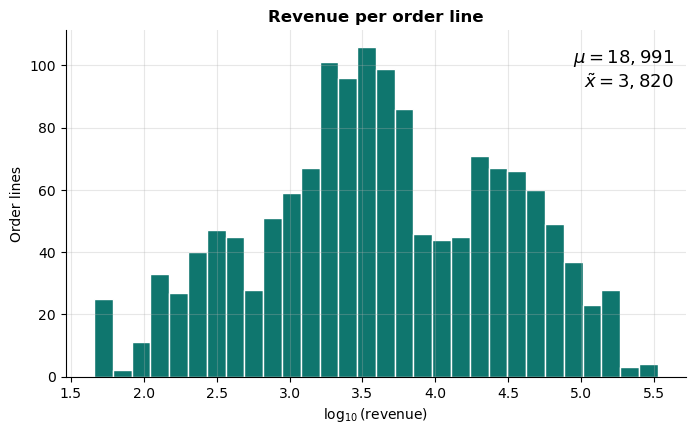

In [2]:
rev = sales["revenue"]
fig, ax = plt.subplots()
ax.hist(np.log10(rev), bins=30, edgecolor="white")
ax.text(0.98, 0.95, rf"$\mu = {rev.mean():,.0f}$" + "\n" + rf"$\tilde{{x}} = {rev.median():,.0f}$",
        transform=ax.transAxes, ha="right", va="top", fontsize=13)          # position as a fraction of the Axes
ax.set(title="Revenue per order line", xlabel=r"$\log_{10}$(revenue)", ylabel="Order lines")
plt.show()

---
## 2. Shaded regions

**Use it when:** a period or a range matters more than any single point: a season, a campaign, a target zone.

`ax.axvspan(start, end)` shades a stretch of the x-axis, and `ax.axhspan(low, high)` a stretch of the y-axis.

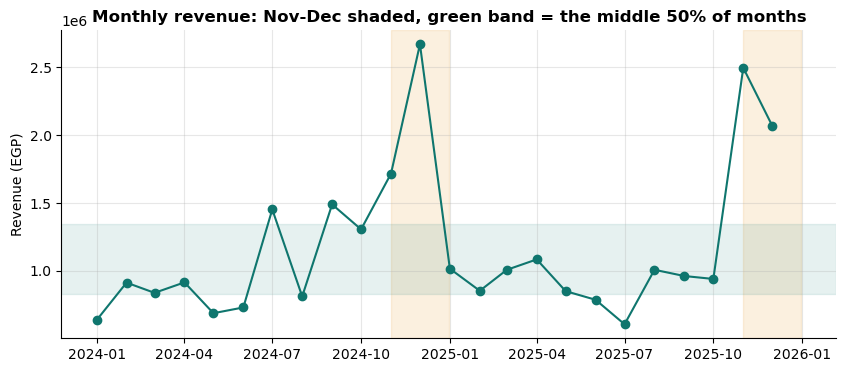

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_month.index, by_month.values, marker="o")
for year in [2024, 2025]:
    ax.axvspan(pd.Timestamp(f"{year}-11-01"), pd.Timestamp(f"{year}-12-31"), color="#E89B2D", alpha=0.15)
ax.axhspan(by_month.quantile(0.25), by_month.quantile(0.75), color="#0F766E", alpha=0.1)
ax.set(title="Monthly revenue: Nov-Dec shaded, green band = the middle 50% of months", ylabel="Revenue (EGP)")
plt.show()

---
## 3. Second y-axis

**Use it when:** two measures have different units and really belong together, like order **counts** and revenue in **EGP**.

`ax.twinx()` adds a second Axes that shares the x-axis and has its own y-axis on the right. Use it sparingly: with two scales, the reader can make any line look bigger than the other.

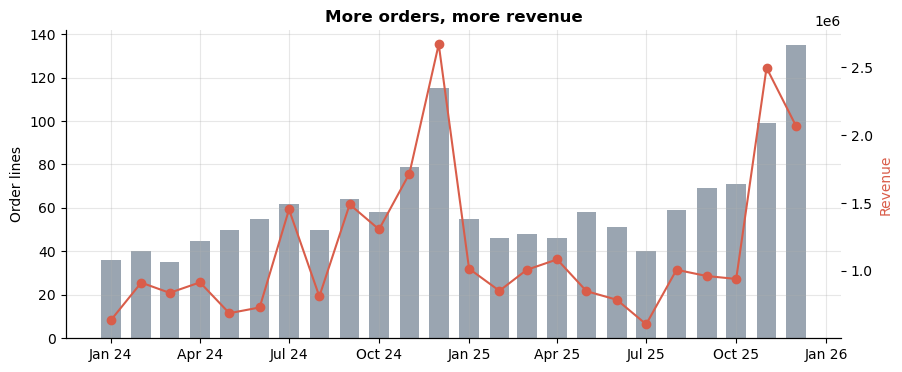

correlation between monthly order lines and revenue: 0.87


In [4]:
m = sales.set_index("order_date").resample("MS").agg({"order_id": "count", "revenue": "sum"})

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(m.index, m["order_id"], width=20, color="#9AA5B1", label="order lines")
ax1.set_ylabel("Order lines")
ax2 = ax1.twinx()
ax2.plot(m.index, m["revenue"], color="#D95D4A", marker="o", label="revenue")
ax2.set_ylabel("Revenue", color="#D95D4A")
ax2.grid(False)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax1.set_title("More orders, more revenue")
plt.show()
print(f"correlation between monthly order lines and revenue: {m['order_id'].corr(m['revenue']):.2f}")

---
## 4. `stackplot`

**Use it when:** you want the total over time **and** what it's made of.

Each band sits on top of the one below, so the top edge is the total. Only the bottom band is easy to read exactly, so keep the biggest group there.

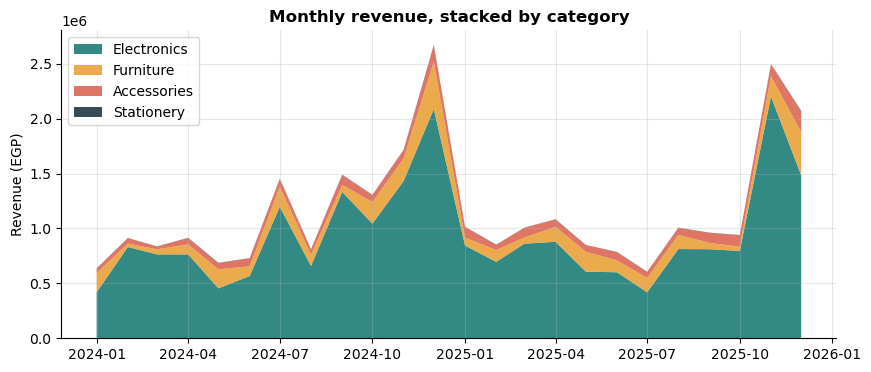

In [5]:
by_cat = sales.pivot_table(index=sales["order_date"].dt.to_period("M").dt.to_timestamp(), columns="category",
                           values="revenue", aggfunc="sum").fillna(0)
by_cat = by_cat[by_cat.sum().sort_values(ascending=False).index]          # biggest at the bottom

fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(by_cat.index, by_cat.T.values, labels=by_cat.columns, alpha=0.85)
ax.legend(loc="upper left")
ax.set(title="Monthly revenue, stacked by category", ylabel="Revenue (EGP)")
plt.show()

---
## 5. `errorbar`

**Use it when:** you computed the means and their uncertainty yourself, and want to draw exactly those numbers. (If you have the raw rows, Seaborn's `barplot` does it for you.)

Here the error is the **standard error** of the mean: `std / √n`, which pandas gives us as `sem`.

                mean     sem
category                    
Stationery     248.0    10.0
Accessories   3041.0    91.0
Furniture    13484.0   845.0
Electronics  57987.0  2624.0


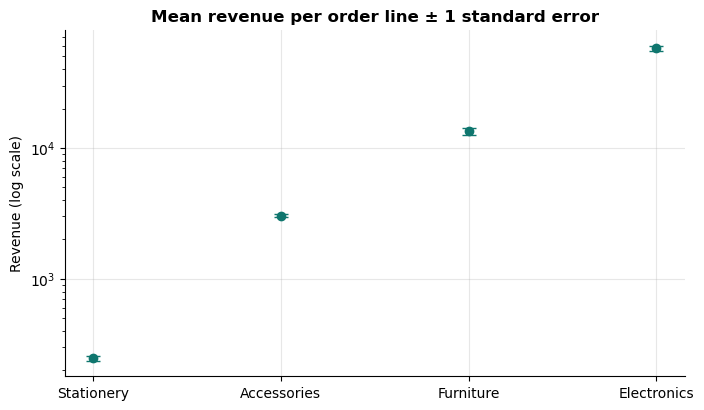

In [6]:
stats = sales.groupby("category")["revenue"].agg(["mean", "sem"]).sort_values("mean")
print(stats.round(0))

fig, ax = plt.subplots()
ax.errorbar(stats.index, stats["mean"], yerr=stats["sem"], fmt="o", capsize=5, color="#0F766E")
ax.set_yscale("log")
ax.set(title="Mean revenue per order line ± 1 standard error", ylabel="Revenue (log scale)")
plt.show()

---
## 6. `hexbin`

**Use it when:** you have so many points that a scatter plot becomes a solid blob.

It cuts the plane into hexagons and colours each one by how many points fall inside, so dense areas stop hiding each other.

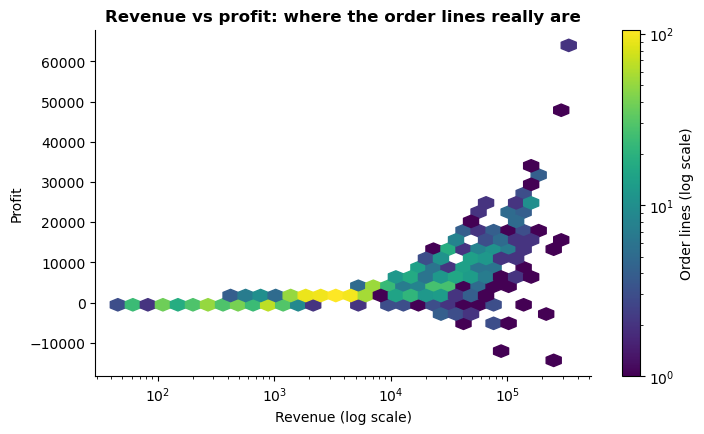

In [7]:
fig, ax = plt.subplots()
hb = ax.hexbin(sales["revenue"], sales["profit"], gridsize=30, bins="log", mincnt=1, cmap="viridis", xscale="log")
fig.colorbar(hb, label="Order lines (log scale)")
ax.grid(False)
ax.set(title="Revenue vs profit: where the order lines really are", xlabel="Revenue (log scale)", ylabel="Profit")
plt.show()

---
## 7. 3D plots

**Use it when:** the third dimension *is* the point, which is rare. Mostly for a talk, or a shape you can rotate.

`fig.add_subplot(projection="3d")` gives a 3D Axes with the same methods (`plot`, `scatter`, `bar`, …), just with a third coordinate, plus `view_init(elev, azim)` to move the camera.

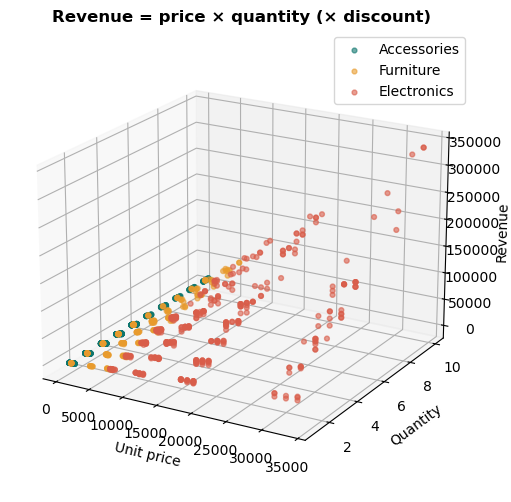

In [8]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(projection="3d")
for cat in ["Accessories", "Furniture", "Electronics"]:
    part = sales[sales["category"] == cat]
    ax.scatter(part["unit_price"], part["quantity"], part["revenue"], s=12, alpha=0.6, label=cat)
ax.set(xlabel="Unit price", ylabel="Quantity", zlabel="Revenue", title="Revenue = price × quantity (× discount)")
ax.view_init(elev=20, azim=-60)            # camera height and rotation, in degrees
ax.legend()
plt.show()

Impressive, right? Now try to read off the exact revenue of one dot. You can't. Perspective distorts the heights and points hide behind each other. In real work, the same information is almost always clearer in 2D, with `hue` or `col=` for the third variable.

---
## 8. Racing bars

**Use it when:** you're telling a story of change over time in a talk. In a written report, use a line chart.

Bars race each other as the months go by. `matplotlib.animation.FuncAnimation(fig, draw, frames=n)` calls your function `draw(i)` once for every frame, and `draw` redraws the chart for month `i`. Then you show it in the notebook (`HTML(anim.to_jshtml())`) or save it as a GIF (`writer="pillow"`) or MP4 (`writer="ffmpeg"`).

(There's a package called `bar_chart_race` that does this in one call, but it's no longer maintained and breaks with current pandas, so we build our own. It's only 15 lines.)

In [9]:
from matplotlib import animation
from IPython.display import HTML

Path("figures").mkdir(exist_ok=True)

# cumulative revenue per product: one row per month, one column per product
cum = (sales.pivot_table(index=sales["order_date"].dt.to_period("M"), columns="product_name",
                         values="revenue", aggfunc="sum")
            .fillna(0).cumsum())
print(cum.shape, "-> one frame per month")
color_of = dict(zip(cum.columns, plt.cm.tab20.colors))          # each product keeps its colour

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=80)

def draw(i):
    ax.clear()
    top = cum.iloc[i].nlargest(8).sort_values()                 # top 8, biggest on top
    bars = ax.barh(top.index, top.values, color=[color_of[p] for p in top.index])
    ax.bar_label(bars, fmt="{:,.0f}", padding=3)
    ax.set_xlim(0, cum.values.max() * 1.15)
    ax.xaxis.set_major_formatter("{x:,.0f}")
    ax.set_title(f"Cumulative revenue by product, up to {cum.index[i].strftime('%b %Y')}")

anim = animation.FuncAnimation(fig, draw, frames=len(cum), interval=400)
anim.save("figures/racing_bars.gif", writer="pillow", fps=3)
plt.close(fig)                       # show the animation below, not a static last frame
HTML(anim.to_jshtml())

(24, 11) -> one frame per month


Watch the order change: the Laptop leads in January 2024, the Phone overtakes it the very next month and never looks back, and the Desk drops from 2nd to 5th.

---
# Part 2: Seaborn

---
## 9. `stripplot`

**Use it when:** you want to see every single row in each group.

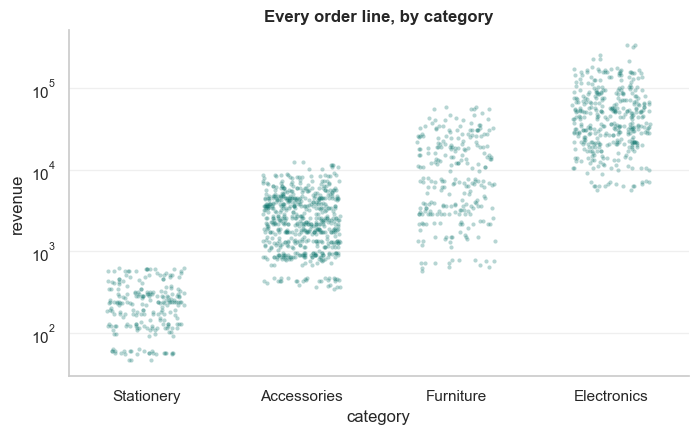

In [10]:
sns.set_theme(style="whitegrid", palette=COLORS)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
order = ["Stationery", "Accessories", "Furniture", "Electronics"]

fig, ax = plt.subplots()
sns.stripplot(data=sales, x="category", y="revenue", order=order, log_scale=True, alpha=0.3, size=3, jitter=0.25, ax=ax)
ax.set_title("Every order line, by category")
plt.show()

⚠️ Look at the Accessories column: hundreds of dots on top of each other, a blob. That's **overplotting**. Fight it with `alpha`, smaller dots or a sample, or switch to a box or violin plot, which summarise instead.

---
## 10. `swarmplot`

**Use it when:** you have a **small** group and want every row visible, with no dot hiding another.

It's a strip plot that pushes the dots apart. On thousands of rows it runs out of room, so keep it for a few hundred at most.

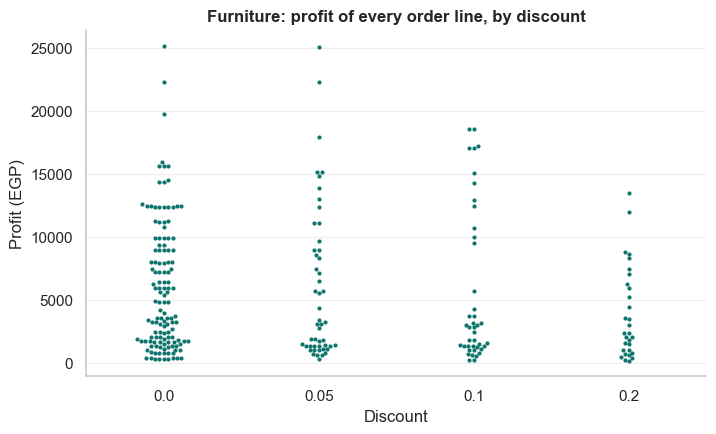

In [11]:
furniture = sales[sales["category"] == "Furniture"]

fig, ax = plt.subplots()
sns.swarmplot(data=furniture, x="discount", y="profit", size=3, ax=ax)
ax.set(title="Furniture: profit of every order line, by discount", xlabel="Discount", ylabel="Profit (EGP)")
plt.show()

---
## 11. `pointplot`

**Use it when:** you're comparing how a mean **changes** across ordered groups. Slopes are easier to compare than bar heights.

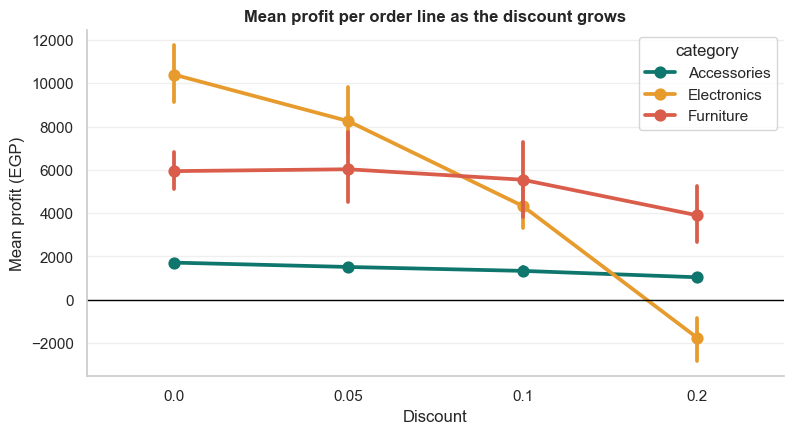

In [12]:
big = sales[sales["category"].isin(["Accessories", "Furniture", "Electronics"])]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.pointplot(data=big, x="discount", y="profit", hue="category", ax=ax)
ax.axhline(0, color="black", lw=1)
ax.set(title="Mean profit per order line as the discount grows", xlabel="Discount", ylabel="Mean profit (EGP)")
plt.show()

Electronics falls from about 10,400 EGP at no discount to a loss of about 1,750 at 20%. The other two lines barely move.

---
## 12. `ecdfplot`

**Use it when:** your question is *"what share of the rows is below X?"*

For each value on the x-axis, the curve gives the share of rows at or below it. No bins to choose, and groups of different sizes compare cleanly.

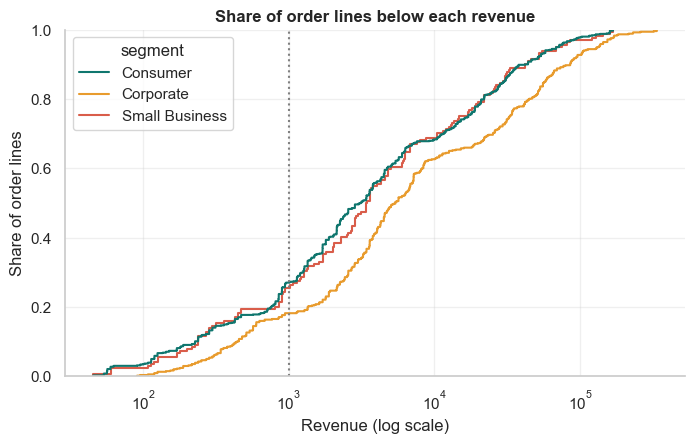

segment
Consumer          0.27
Corporate         0.18
Small Business    0.26
Name: revenue, dtype: float64

In [13]:
known = sales[sales["segment"] != "Unknown"]

fig, ax = plt.subplots()
sns.ecdfplot(data=known, x="revenue", hue="segment", log_scale=True, ax=ax)
ax.axvline(1000, color="grey", ls=":")
ax.set(title="Share of order lines below each revenue", xlabel="Revenue (log scale)", ylabel="Share of order lines")
plt.show()

known.groupby("segment")["revenue"].apply(lambda r: (r <= 1000).mean()).round(2)

Read it at the dotted line: 18% of Corporate order lines are 1,000 EGP or less, against 27% for Consumer. The Corporate curve sits to the right because its orders are bigger.

---
## 13. `lmplot`

**Use it when:** you want a straight trend line through a scatter plot, one line per group.

`lmplot` is figure-level, so it also takes `col=`. Its axes-level sister is `regplot`.

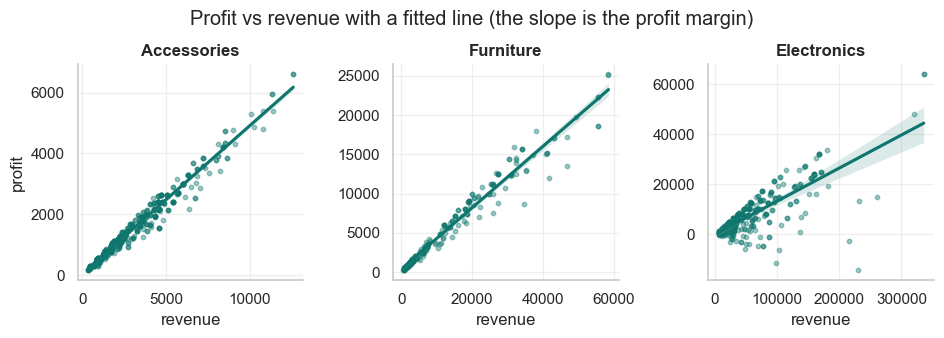

In [14]:
g = sns.lmplot(data=big, x="revenue", y="profit", col="category", col_order=["Accessories", "Furniture", "Electronics"],
               height=3.2, aspect=1, facet_kws={"sharex": False, "sharey": False}, scatter_kws={"s": 10, "alpha": 0.4})
g.set_titles("{col_name}")
g.figure.suptitle("Profit vs revenue with a fitted line (the slope is the profit margin)", y=1.05)
plt.show()

The steeper the line, the larger the share of each pound kept as profit: around 0.49 for Accessories and 0.39 for Furniture, against only 0.13 for Electronics. Big sales, thin margin.

---
## 14. `jointplot`

**Use it when:** you want a relationship between two columns and each one's distribution, in one figure.

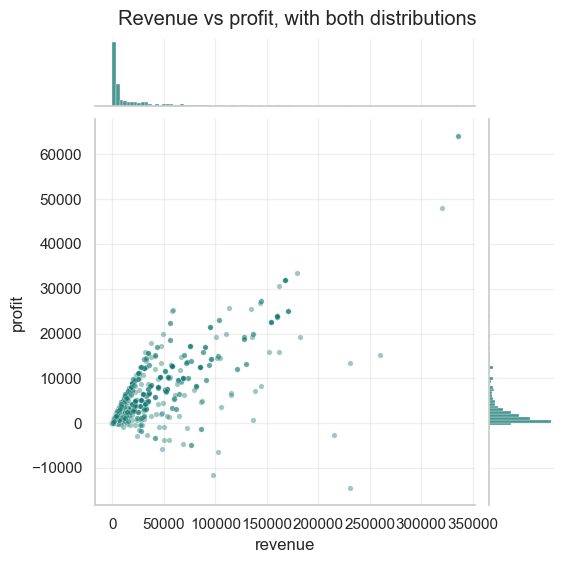

In [15]:
g = sns.jointplot(data=sales, x="revenue", y="profit", height=5.5, alpha=0.4, s=15)
g.figure.suptitle("Revenue vs profit, with both distributions", y=1.02)
plt.show()

---
## 15. `clustermap`

**Use it when:** you have a table of groups and want to find **which ones behave alike**.

It's a heatmap that reorders rows and columns so similar ones sit together; the tree on the side shows how they join. `z_score=1` compares each column on its own scale, otherwise Electronics would swallow every colour.

category            Accessories  Electronics  Furniture  Stationery
region                                                             
Alexandria & Coast        0.057        0.844      0.097       0.002
Canal                     0.055        0.845      0.099       0.001
Delta                     0.085        0.750      0.162       0.004
Greater Cairo             0.065        0.807      0.126       0.002
Upper Egypt               0.068        0.810      0.121       0.001


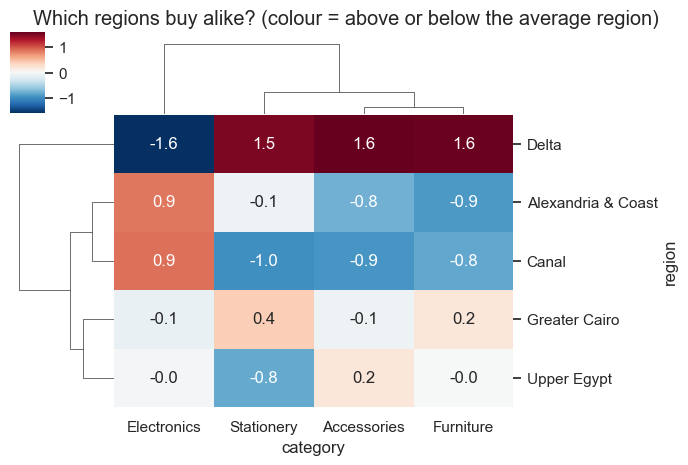

In [16]:
known_region = sales[sales["region"] != "Unknown"]
share = known_region.pivot_table(index="region", columns="category", values="revenue", aggfunc="sum").fillna(0)
share = share.div(share.sum(axis=1), axis=0)                  # each region adds up to 1
print(share.round(3))

g = sns.clustermap(share, z_score=1, cmap="RdBu_r", center=0, annot=True, fmt=".1f", figsize=(7, 4.5))
g.figure.suptitle("Which regions buy alike? (colour = above or below the average region)", y=1.03)
plt.show()

The tree pairs Alexandria & Coast with Canal: Electronics is about 84% of revenue in both. The Delta stands alone, at 75% Electronics and 16% Furniture.

---
## Summary

| Chart | Code | Use it when |
|---|---|---|
| Maths in text | `r"$\mu = 5$"`, `transform=ax.transAxes` | a label needs a formula |
| Shaded region | `ax.axvspan(a, b)`, `ax.axhspan(a, b)` | a period or range matters |
| Second y-axis | `ax2 = ax.twinx()` | two units that belong together |
| Stacked area | `ax.stackplot(x, ys, labels=...)` | total over time and its parts |
| Error bars | `ax.errorbar(x, y, yerr=...)` | you computed the uncertainty yourself |
| Hexagon density | `ax.hexbin(x, y, gridsize=30)` | too many points for a scatter |
| 3D | `fig.add_subplot(projection="3d")` | the third dimension is the point |
| Racing bars | `animation.FuncAnimation(fig, draw, frames=n)` | a talk about change over time |
| Every row | `sns.stripplot`, `sns.swarmplot` | small groups, individual rows |
| Mean with trend | `sns.pointplot` | comparing slopes across ordered groups |
| Share below X | `sns.ecdfplot` | "what share is below X?" |
| Trend line | `sns.lmplot`, `sns.regplot` | a straight fit through a scatter |
| Relationship + distributions | `sns.jointplot` | both in one figure |
| Similar groups | `sns.clustermap` | which rows behave alike |

**Next:** [Mini EDA](06_mini_eda.ipynb): the charts of this part used together on one question.